# Holter ECG 전처리 2단계: 신호 정제 (필터)

- **앞 단계**: `holter_preprocessing.ipynb` 1단계 (기록 단위 QC). 결과 파일 `results/preprocess/record_qc.csv`, `results/preprocess/window_qc/*.npz`만 읽어서 씀
- **대상**: 1단계 통과 708명 (`record_qc.csv`의 `exclude`가 빈 칸)
- **목표**: 30초 조각을 만들 때 쓸 필터 함수를 정하고, 필터가 ECG 모양을 망가뜨리지 않는지 데이터로 확인
  - `dl_filter`: 딥러닝 입력용, 0.5–40 Hz
  - `r_filter`: R파 검출용, neurokit2 기본값. 3단계에서 "이 창에 박동이 있는가"를 볼 때 도구로만 씀
- 708명의 필터 결과는 **저장하지 않는다**. 6단계에서는 30초 조각의 위치(색인)만 저장하고, 필터는 읽을 때 건다 (708명 전부 저장하면 약 70 GB)
- 근거·이유 표기 규칙은 `holter_preprocessing.ipynb` 맨 위 **판정·전처리 기준**과 같음 (📄 저널 · 🔧 데이터 규칙 · ✋ 자체 기준 / ✅ 확정 · 🔄 확인 중 · ⏸ 보류 · ⬜ 미정). **새 기준이 필요하면 논문부터 찾고 정한다**

## 2단계 기준

> **진행 방식** (2026-10-24): 논문 기준으로 먼저 진행하고, 우리 데이터와 안 맞으면 그때 🔧 데이터 규칙으로 고친다 (고치면 이 표와 아래 결정 기록에 남김)

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 샘플링 | 200 Hz 유지 (다운샘플링 안 함) | 📄 Ramírez 2017 [전문], Shaffer 2017 [전문] | MUSIC 원자료가 200 Hz. "125 Hz 또는 200 Hz면 RSA가 정상일 때 충분할 수 있음" (Shaffer). 한계: "HRV가 매우 낮은 일부 심부전 환자는 더 높은 샘플링이 필요" (Shaffer) | ✅ |
| DL 입력용 필터: 대역 | 0.5–40 Hz | 📄 Ramírez 2017 [전문], K-REDEFINE 2025 [전문] / 0.5 Hz 허용 범위: Kligfield 2007 [전문] | 40 Hz 저역: "전기·근육 잡음을 제거하면서 QRS·T파 분석은 가능하게", 0.5 Hz 고역: "기저선 흔들림 제거" (Ramírez, 같은 MUSIC 데이터). K-REDEFINE은 0.67–40 Hz (원문에 이유 없음). Kligfield: 심전도의 가장 느린 성분은 심박수이고, 위상 왜곡 없는 디지털 필터면 고역을 "0.67 Hz 이하"까지 허용 (1309쪽). ⚠️ 한계: Kligfield는 고주파 경계를 40 Hz로 낮추면 "진단 분류에 쓰는 진폭 측정이 무효"가 된다고 함 (1310쪽, 진단용 12유도 기준). 우리는 사람이 진폭을 재서 진단하는 용도가 아니라 딥러닝 입력이고, 같은 데이터의 Ramírez가 40 Hz를 씀 | ✅ |
| DL 입력용 필터: 방향 | 앞→뒤, 뒤→앞으로 두 번 (`sosfiltfilt`, 위상 지연 없음) | 📄 Kligfield 2007 [전문], Luo 2010 [전문] | 한 번만 걸면 QRS 끝~ST 시작처럼 신호가 급하게 바뀌는 곳에서 위상 왜곡이 생겨 ST 높이가 휨. 거꾸로 한 번 더 거는 필터는 왜곡이 없고, 저장된 신호에만 쓸 수 있음 (Kligfield 1309쪽). 한쪽으로 건 0.5 Hz 필터는 ST를 크게 왜곡, 앞뒤로 거는 필터는 왜곡 없음 (Luo 490쪽, 그림 4) | ✅ |
| DL 입력용 필터: 종류·차수 | 버터워스 4차 | 📄 Frontiers Cardiovasc Med 2026 [전문] (같은 설정 사용 사례) | **원문에 이유 없음.** 장시간 Holter 딥러닝 연구가 같은 대역(0.5–40 Hz)에 버터워스 4차를 씀 (데이터는 360 Hz라 우리와 다름). 다른 Holter AI 연구는 2차 사용 (EHJ Digit Health 2024, 이유 없음). 차수를 비교한 저널 논문은 찾지 못함. 차수가 높을수록 경계 밖 잡음은 더 지우지만 큰 신호 변화 뒤 출렁임(ringing)이 커짐 (Luo 492~493쪽) → 2-2·2-3에서 확인. 확인 기준: 고역 필터가 1 Hz에서 0.5 dB(약 5.6%) 넘게 깎지 않을 것 (Luo 492쪽, 0.67 Hz 필터에 대한 권고) | ✅ (2-1·2-2·2-3 확인) |
| R파 검출용 필터 | neurokit2 기본: 0.5 Hz 고역 (버터워스 5차, 앞뒤 두 번) + 4샘플 이동평균 (50 Hz 제거, 앞뒤 두 번) | 📄 Kristof 2024 [전문] (도구 기본값) | neurokit 검출기가 공개 검출기 18개 중 최상위 (Kristof). 값은 설치된 neurokit2 0.2.13 소스에서 확인. ⚠️ 4샘플 이동평균은 50 Hz만 지우는 게 아니라 고주파 전체를 깎음 (계산상 15 Hz 약 75%, 40 Hz 약 6% 남음) → 1단계 노트북 표의 "저역 필터 없음"은 고쳐야 함. 2-1에서 확인함 (15 Hz 0.751, 40 Hz 0.063, 50 Hz 0) | ✅ |
| 필터를 거는 위치 | **B 방식: 버린 구간에서 기록을 끊고, 깨끗한 덩어리(깨끗한 창이 이어진 구간)마다 따로 필터**. 30초로 자르기 전에 건다 | 📄 Widmann 2015 [전문], de Cheveigné 2019 [전문] / 구현 사례 (참고, 저널 아님): MNE-Python, EEGLAB 기본 동작 | "이어진 데이터에 필터를 걸 것", "신호가 끊긴 곳을 가로질러 필터를 걸지 말 것" (Widmann 38·45쪽). "조각으로 자를 거면 이어진 데이터에 먼저 필터" (de Cheveigné 288쪽). 두 논문은 뇌파 논문이지만 필터의 성질은 신호 종류와 상관없음. 우리 시험(2-3 ②-2): B는 출렁임 1.68초로 계단 크기와 상관없음. 그냥 전체에 걸면(A) 최대 3.46초, 최대 1.78 mV(QRS 높이만큼) 휨 | ✅ |
| 덩어리 끝 여유 | 덩어리 양 끝 **3.5초**를 "사용 불가"로 표시 (필터 출렁임이 남는 부분) | 🔧 데이터 규칙 (2-3) / 보조: van Driel 2021 [전문] | **몇 초인지 적은 논문은 없음** (Holter·심전도·뇌파 논문 검색). van Driel: 필터 출렁임이 "앞뒤로 몇 초까지" 가고, 보통 "충분한 여유 구간"을 둔다 (6·11쪽, 숫자 없음). 우리 시험: 실제 경계 99%의 출렁임 3.5초 이하 (②-1), B 방식 1.68초 (②-2). 덩어리 길이가 10초 단위라 여유가 5초 이하면 결과가 똑같고, 3.5초로 해도 30초 조각이 0.05%만 줄어듦 (③) → 넉넉한 3.5초로 정함 | ✅ |
| 유도 기준 | 30초 조각은 **그 환자에게 있는 유도가 모두 깨끗해야** 사용 (3채널 입력이 기본). 유도별 개수는 참고로 같이 셈 | ✋ 자체 기준 (팀 계획) | **저널 기준 없음.** 다유도 Holter 딥러닝 논문도 "한 유도만 나쁠 때"를 어떻게 했는지 안 적음 (EHJ Digit Health 2024: 품질 낮은 30분 창 13% 제외, 어느 유도 기준인지 없음). 12유도 딥러닝은 모든 유도를 한꺼번에 넣는 방식이 가장 흔함. ③: 이 기준으로 해도 X 유도 하나만 볼 때보다 조각이 0.3%만 적음 | ✅ (DL 설계 때 다시 봄) |
| Z 유도 없는 환자 | 1단계 통과 708명 중 **30명은 X·Y 두 유도만 있음** (생존 27, SCD 3). 3채널 입력에서 **Z 자리를 0으로 채움**. 6단계 조각 목록에 유도 수(2/3)를 같이 저장. 팀 계획: "3유도 환자만" vs "2·3유도 섞음 (Z = 0)" 성능 비교 | 📄 npj Cardiovasc Health 2024 (MCMA) [전문] | 없는 유도 자리를 0으로 채워 채널 형식을 유지했고, 같은 유도를 복사해 채우는 것보다 좋았음. ⚠️ 이 논문은 유도 1개로 12유도 파형을 **복원**하는 연구 → 0으로 채워도 **SCD 예측 성능**이 유지되는지는 우리 비교 실험으로 확인. SCD 비율이 2유도 10% (3/30), 3유도 12.4% (84/678)로 비슷해서 "Z가 0이면 SCD" 같은 엉뚱한 단서가 될 가능성은 낮음 | ✅ 방법 / 🔄 성능은 DL에서 비교 |

### 근거 논문 (2단계에서 추가)

| 논문 | 저널 | 확인 범위 | 어디에 썼나 |
|---|---|---|---|
| Kligfield P, et al. Recommendations for the standardization and interpretation of the electrocardiogram, Part I (AHA/ACCF/HRS) | *Circulation* 2007;115:1306 (*JACC* 2007;49:1109 동시 게재) | 전문 (PDF) | 앞뒤 두 번 거는 이유, 0.5 Hz 허용, 40 Hz 한계. 진단용 12유도 심전도 기계 표준 (Holter·딥러닝 연구 아님) |
| Luo S, Johnston P. A review of electrocardiogram filtering | *J Electrocardiol* 2010;43:486 | 전문 (PDF) | 앞뒤 두 번, 출렁임, 1 Hz 확인 기준. 심전도 기기 필터 리뷰 (저자는 기기 회사 소속) |
| Deep learning-based early prediction of life-threatening ventricular arrhythmias using long-term Holter ECG signals | *Front Cardiovasc Med* 2026 (PMC12920577) | 전문 (필터 부분) | 버터워스 4차 0.5–40 Hz 사용 사례 |
| An artificial intelligence–enabled Holter algorithm to identify patients with ventricular tachycardia by analysing their electrocardiogram during sinus rhythm | *Eur Heart J Digit Health* 2024;5:409 | 전문 (필터 부분) | 참고: 앞뒤로 거는 2차 필터 0.67–100 Hz + 50 Hz 제거 |

| Widmann A, Schröger E, Maess B. Digital filter design for electrophysiological data – a practical approach | *J Neurosci Methods* 2015;250:34 | 전문 (PDF) | 끊긴 곳을 가로질러 필터하지 말 것, 이어진 데이터에 필터, 출렁임이 앞뒤로 번짐 (뇌파 논문) |
| de Cheveigné A, Nelken I. Filters: when, why, and how (not) to use them | *Neuron* 2019;102:280 | 전문 (PDF) | 자르기 전에 필터, 시험 신호(계단·한 점 튐)로 필터 반응 확인 (뇌파·신경 신호 논문) |
| van Driel J, Olivers CNL, Fahrenfort JJ. High-pass filtering artifacts in multivariate classification of neural time series data | *J Neurosci Methods* 2021;352:109080 | 전문 (PDF) | 보조: 출렁임이 앞뒤로 몇 초 가고 여유 구간을 둠 (숫자 없음). 다른 종류 필터(FIR)만 시험했고 "버터워스 4차는 결과가 조금 다를 수 있다"고 씀 (15쪽) |
| Multi-channel masked autoencoder and comprehensive evaluations for reconstructing 12-lead ECG from arbitrary single-lead ECG (MCMA) | *npj Cardiovasc Health* 2024 (doi 10.1038/s44325-024-00036-4) | 전문 (Europe PMC) | 없는 유도를 0으로 채워 채널 형식 유지 (유도 1개 → 12유도 복원 연구) |

**참고 (저널 아님, 구현 사례)**: MNE-Python `Raw.filter` 설명 "제외한 구간의 양쪽은 독립된 신호처럼 따로 필터한다", EEGLAB 기본 필터는 끊긴 지점("boundary")을 가로질러 걸지 않음 → B 방식이 뇌파 분석 도구의 기본 동작

**확인했지만 차수·종류가 없던 논문**: Ramírez 2017, K-REDEFINE 2025 (전문), DeepHHF 2026 (arXiv판, "filtering"이라고만 씀)

**진행 순서**

| 소단계 | 내용 | 상태 |
|---|---|---|
| 2-0 | 환경 설정, 기준값 | ✅ |
| 2-1 | 필터 함수 + 주파수 응답 (주파수별로 신호가 얼마나 남는지) | ✅ |
| 2-2 | 필터 전후 그림 (정상 ECG P0307 X·Y, 1-6 ③ 잡음 창) | ✅ |
| 2-3 | 필터를 어디에 걸지: 기록 전체 vs 30초 조각마다, 버린 창 옆으로 번지는 출렁임 | ✅ |
| 2-4 | 2단계 정리 (쉬운 설명) | ✅ |

## 결정 기록 (2단계)

| 날짜 | 결정 | 근거 / 메모 |
|---|---|---|
| 2026-10-24 | 2단계를 별도 노트북으로 진행. 필터 결과는 저장하지 않고 6단계에서 읽을 때 적용 | 708명 전부 저장하면 약 70 GB |
| 2026-10-24 | 논문 기준으로 먼저 진행하고, 데이터와 안 맞으면 🔧 데이터 규칙으로 수정 | 팀 방침 |
| 2026-10-24 | DL 입력용 필터: 버터워스 4차, 0.5–40 Hz, 앞뒤 두 번 | Ramírez 2017 (대역), Kligfield 2007·Luo 2010 (방향), Front Cardiovasc Med 2026 (차수 사례, 이유 없음). 2-2·2-3 확인 후 확정 |
| 2026-10-25 | 나쁜 구간은 **지우지 않고 "사용 불가" 표시만** 함. 6단계에서 30초 조각 목록에 사용 가능/불가 표시를 같이 저장. 조각 단위 모델이면 표시된 조각 제외, 24시간 순서 모델이면 기본은 가리기(마스크)이고 그대로 넣는 방식과 비교 | 조각·창 단위 모델은 나쁜 구간 제외 (EHJ Digit Health 2024 AI-Holter: 신호 품질 낮은 30분 창 13.1% 제외, Gadaleta 2023). 24시간 순서 모델은 전부 사용 (K-REDEFINE 2025: 9초 조각 9,600개 전부, DeepHHF 2026: 24시간 통째). 시간 순서(하루 중 시각)를 유지하려고 자리는 남김 |
| 2026-10-25 | 필터 거는 위치 = **B 방식** (버린 구간에서 끊고 깨끗한 덩어리마다 따로 필터) | Widmann 2015, de Cheveigné 2019. 2-3 ②-2: 출렁임 1.68초, 계단 크기와 상관없음 |
| 2026-10-25 | 덩어리 양 끝 **3.5초** "사용 불가" | 논문에 숫자 없음 → 🔧. 2-3 ③: 30초 조각 0.05%만 줄어듦, 여유 5초 이하면 결과 같음 |
| 2026-10-25 | 30초 조각은 **있는 유도가 모두 깨끗해야** 사용 | 저널 기준 없음. 12유도 딥러닝에서 가장 흔한 방식(모든 유도 한꺼번에 입력). DL 입력 정할 때 다시 봄 |
| 2026-10-25 | **Z 없는 30명**(생존 27, SCD 3): Z = 0으로 채움. 6단계 조각 목록에 유도 수 저장. 팀 비교: 3유도만 vs 섞음 | npj Cardiovasc Health 2024 (MCMA). 성능 영향은 DL 비교 실험으로 확인 |
| 2026-10-25 | 3단계(신호 품질 검사) 뒤에 2-3 ③을 다시 실행 | 3단계에서 버리는 창이 늘면 경계도 늘어남 → 손실이 여전히 작은지 확인 |


## 2-0. 환경 설정, 기준값

In [7]:
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import wfdb
import neurokit2 as nk
from scipy import signal as sps

# 한글 폰트
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

# 경로: 1단계 노트북과 같음 (notebooks/ 안에서 실행되든 프로젝트 루트에서 실행되든 동작하도록)
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
HOLTER = Path("/mnt/c/data/music/Holter_ECG")
OUT = ROOT / "results" / "preprocess"          # 1단계 결과가 있는 폴더
WIN_DIR = OUT / "window_qc"                    # 1단계 창별 판정 (환자별 npz)

# 1단계 결과 읽기: 통과 708명만
qc = pd.read_csv(OUT / "record_qc.csv")
qc_pass = qc[qc["exclude"].isna()].copy()      # exclude가 빈 칸 = 1단계 통과
print("1단계 통과:", len(qc_pass), "명 (생존", (qc_pass["label_scd"] == 0).sum(), "/ SCD", (qc_pass["label_scd"] == 1).sum(), ")")

1단계 통과: 708 명 (생존 621 / SCD 87 )


In [8]:
# 2단계 기준값: 여기서만 바꾸고, 바꾸면 위 기준 표와 결정 기록에 남기기

# DL 입력용 (대역: Ramírez 2017 / 방향: Kligfield 2007, Luo 2010 / 차수: Front Cardiovasc Med 2026 사례)
DL_BAND = (0.5, 40.0)   # 통과시킬 주파수 범위 (Hz): 0.5 Hz 고역 = 기저선 흔들림 제거, 40 Hz 저역 = 전기·근육 잡음 제거
DL_ORDER = 4            # 버터워스 차수 (경계에서 얼마나 가파르게 깎는지). 필터는 앞뒤로 두 번 건다 (sosfiltfilt)
MIN_GAIN_1HZ = 10 ** (-0.5 / 20)   # 확인 기준 (Luo 2010): 1 Hz에서 0.5 dB 넘게 깎지 않을 것 = 원래 크기의 94.4% 이상 남아야 함

# R파 검출용 (neurokit2 기본 = nk.ecg_clean(method="neurokit")과 같은 값, 3단계 도구)
R_HP = 0.5              # 0.5 Hz 고역
R_HP_ORDER = 5          # 버터워스 5차
POWERLINE = 50          # 전원 주파수 (스페인 50 Hz): 50 Hz 한 주기 길이(200 Hz에서 4샘플) 이동평균

## 2-1. 필터 함수 + 주파수 응답

- `dl_filter(x_mv, fs)`: DL 입력용. 버터워스 `DL_ORDER`차 0.5–40 Hz를 앞뒤로 두 번 (`sps.sosfiltfilt`). 2-2, 2-3, 6단계에서 다시 씀
- `r_filter(x_mv, fs)`: R파 검출용. `nk.ecg_clean(method="neurokit")` 그대로. 3단계에서 씀
- 입력은 **mV 단위 실수 배열** (정수 원본값 ÷ gain)
- 주파수 응답: 신호를 넣지 않고 필터 계수만으로 "주파수별로 크기가 몇 배로 남는지" 계산. 앞뒤 두 번이라 한 번 걸 때 값의 제곱
- 확인할 것
  - DL 필터: 0.5·40 Hz에서 약 0.5, 1~15 Hz는 거의 1, **1 Hz에서 0.944 이상** (Luo 기준), 33.3 Hz는 대부분 남음 (→ 3단계), 50 Hz는 조금 남음
  - R파 필터: 15 Hz 약 0.75, 40 Hz 약 0.06, 50 Hz 0 → 맞으면 1단계 노트북 표 "저역 필터 없음" 문구 수정

,주파수(Hz),의미,DL 필터,R파 필터
0,0.1,기저선 흔들림 (호흡·움직임),0.000,0.000
1,0.5,고역 경계,0.500,0.500
2,1.0,느린 심박 (60 bpm),0.997,0.998
3,5.0,T파·P파 대역,1.000,0.970
4,15.0,QRS 주성분,1.000,0.751
5,33.3,1-6 ③ 잡음 A (fs/6),0.870,0.188
6,40.0,저역 경계,0.500,0.063
7,50.0,전원 잡음 (1-6 ③ 잡음 B),0.069,0.000
8,67.0,잡음 A의 2배음,0.001,0.064


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


DL 필터 1 Hz: 0.9970 (기준 0.9441 이상) → 통과


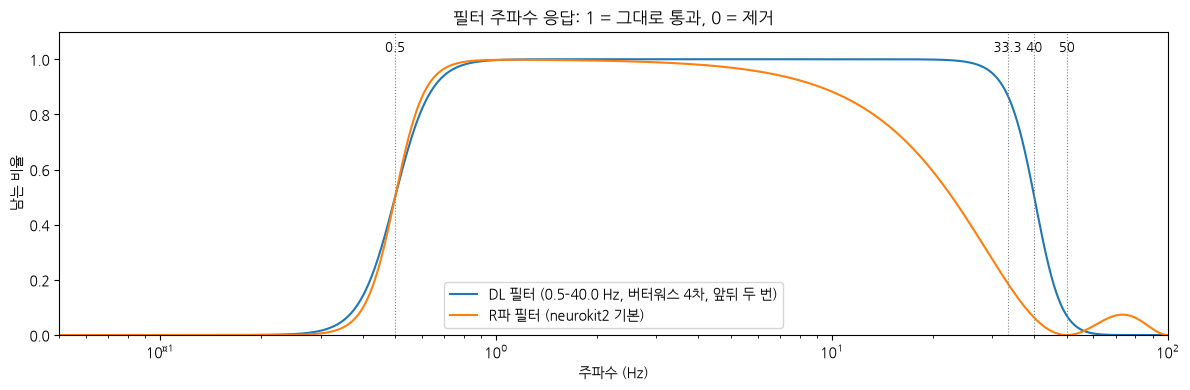

In [9]:
# 2-1. 필터 함수 + 주파수 응답: 주파수마다 신호 크기가 몇 배로 남는지 (1 = 그대로, 0 = 완전히 제거)

def dl_filter(x_mv, fs):
    """DL 입력용 0.5–40 Hz 대역 통과. 버터워스를 앞→뒤, 뒤→앞으로 두 번 걸어(sosfiltfilt) 파형이 시간축으로 밀리지 않음"""
    sos = sps.butter(DL_ORDER, DL_BAND, btype="bandpass", fs=fs, output="sos")   # 필터 계수 (sos = 계산이 안정적인 형식)
    return sps.sosfiltfilt(sos, x_mv)

def r_filter(x_mv, fs):
    """R파 검출용 (3단계 도구): neurokit2 기본 정제"""
    return nk.ecg_clean(x_mv, sampling_rate=fs, method="neurokit")

# ① 주파수 응답 계산: 필터를 한 번 걸 때의 응답 → 앞뒤 두 번 걸므로 크기를 제곱
fs = 200
f = np.linspace(0.01, fs / 2, 20000)                                              # 0.01 ~ 100 Hz
_, h_dl = sps.freqz_sos(sps.butter(DL_ORDER, DL_BAND, btype="bandpass", fs=fs, output="sos"), worN=f, fs=fs)
_, h_hp = sps.freqz_sos(sps.butter(R_HP_ORDER, R_HP, btype="highpass", fs=fs, output="sos"), worN=f, fs=fs)
n_ma = int(fs / POWERLINE)                                                        # 이동평균 길이 4샘플
_, h_ma = sps.freqz(np.ones(n_ma) / n_ma, worN=f, fs=fs)                          # neurokit의 50 Hz 제거 = 4샘플 이동평균
g_dl = np.abs(h_dl) ** 2                                                          # DL 필터: 남는 비율
g_r = (np.abs(h_hp) * np.abs(h_ma)) ** 2                                          # R파 필터: 고역 × 이동평균

# ② 주요 주파수에서 남는 비율 표
CHECK = {0.1: "기저선 흔들림 (호흡·움직임)", 0.5: "고역 경계", 1: "느린 심박 (60 bpm)", 5: "T파·P파 대역",
         15: "QRS 주성분", 33.3: "1-6 ③ 잡음 A (fs/6)", 40: "저역 경계", 50: "전원 잡음 (1-6 ③ 잡음 B)", 67: "잡음 A의 2배음"}
rows = [{"주파수(Hz)": c, "의미": m,
         "DL 필터": np.interp(c, f, g_dl), "R파 필터": np.interp(c, f, g_r)} for c, m in CHECK.items()]
display(pd.DataFrame(rows).round(3))

# ③ Luo 2010 확인 기준: 1 Hz에서 94.4% 이상 남는지
g1 = np.interp(1.0, f, g_dl)
print(f"DL 필터 1 Hz: {g1:.4f} (기준 {MIN_GAIN_1HZ:.4f} 이상) →", "통과" if g1 >= MIN_GAIN_1HZ else "미달")

# ④ 그림: 가로축은 로그 (0.1 Hz와 50 Hz를 한 그림에서 보려고)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(f, g_dl, label=f"DL 필터 ({DL_BAND[0]}–{DL_BAND[1]} Hz, 버터워스 {DL_ORDER}차, 앞뒤 두 번)")
ax.plot(f, g_r, label="R파 필터 (neurokit2 기본)")
for c, txt in [(0.5, "0.5"), (33.3, "33.3"), (40, "40"), (50, "50")]:
    ax.axvline(c, color="gray", ls=":", lw=0.8)
    ax.text(c, 1.03, txt, ha="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(0.05, fs / 2)
ax.set_ylim(0, 1.1)
ax.set_xlabel("주파수 (Hz)")
ax.set_ylabel("남는 비율")
ax.set_title("필터 주파수 응답: 1 = 그대로 통과, 0 = 제거")
ax.legend(loc="lower center")
plt.tight_layout()
plt.show()

📝 **결과 메모** (2026-10-24, 2-1)

- DL 필터 (버터워스 4차 0.5–40 Hz, 앞뒤 두 번): 1 Hz 0.997 → Luo 기준(0.944 이상) **통과**. 5·15 Hz 1.000 → ECG 성분은 그대로
  - 50 Hz 0.069: 전원 잡음 93% 제거 (1~3 mV 잡음이면 0.07~0.2 mV 남음)
  - ⚠️ 33.3 Hz 0.870: 1-6 ③ 잡음 A(박동 없는 기계 떨림)는 필터로 안 지워짐 → 그 구간에는 원래 심전도가 없으므로 3단계에서 구간째 제외
- R파 필터 (neurokit2 기본): 15 Hz 0.751, 40 Hz 0.063, 50 Hz 0 → 4샘플 이동평균이 저역 필터처럼 작동 (계산과 일치)
  - → 1단계 노트북 기준 표 "저역 필터 없음" 문구 수정 필요. R파 검출은 이 정제까지 포함해서 검증된 방식이라 그대로 사용 (Kristof 2024)
  - 33.3 Hz 0.188: 박동 없는 33 Hz 잡음은 R파 검출에서 "박동 없음"으로 보일 가능성 → 3단계에서 확인
- 그림 경고(`\u2212`)는 로그 축 마이너스 기호 글꼴 문제, 결과와 무관


## 2-2. 필터 전후 그림 (실제 신호)

- 보는 것: 10초 창에서 원본(회색)과 필터 후(파랑)를 겹쳐 그림
  - 정상 ECG: 박동 모양·위치가 그대로인지 (앞뒤 두 번 걸어서 위치가 밀리지 않아야 함), 바닥선이 평평해지는지
  - 1-6 ③ 잡음: 33 Hz는 대부분 남고(2-1: 87%), 50 Hz는 대부분 사라지는지(2-1: 7%)
- 대상: P0001 기준 구간(정상 ECG), 1-6 ③ 잡음 창 4개 (같은 판정·같은 방식으로 다시 찾은 창, 주파수 확인함)
- 필터는 10초 창의 앞뒤 1분을 같이 읽어서 걸고 가운데 10초만 봄 (창 끝부분 출렁임을 피하려고). 기록 전체에 걸 때와 차이는 2-3에서 비교


,환자,유도,설명,원본 범위(mV),필터 후 범위(mV),남은 비율,R파 위치 차이(ms)
0,P0001,X,정상 ECG (기준 구간),1.70,1.508,0.887,-5.0
1,P0001,Y,정상 ECG (기준 구간),1.81,1.506,0.832,-5.0
2,P0001,Z,정상 ECG (기준 구간),1.74,1.462,0.840,-5.0
3,P0551,X,"잡음 A: 33 Hz, 박동 없음",0.20,0.160,0.799,NaN
4,P0551,Y,"잡음 A: 33 Hz, 박동 없음",0.04,0.031,0.770,NaN
5,P0551,Z,"잡음 A: 33 Hz, 박동 없음",0.28,0.213,0.761,NaN
6,P0074,X,"잡음 A: 34 Hz, 박동 없음",0.32,0.190,0.593,NaN
7,P0074,Y,"잡음 A: 34 Hz, 박동 없음",0.17,0.115,0.675,NaN
8,P0074,Z,"잡음 A: 34 Hz, 박동 없음",0.23,0.166,0.722,NaN
9,P0765,X,잡음 B: 50 Hz 전원 잡음,2.24,0.843,0.376,NaN


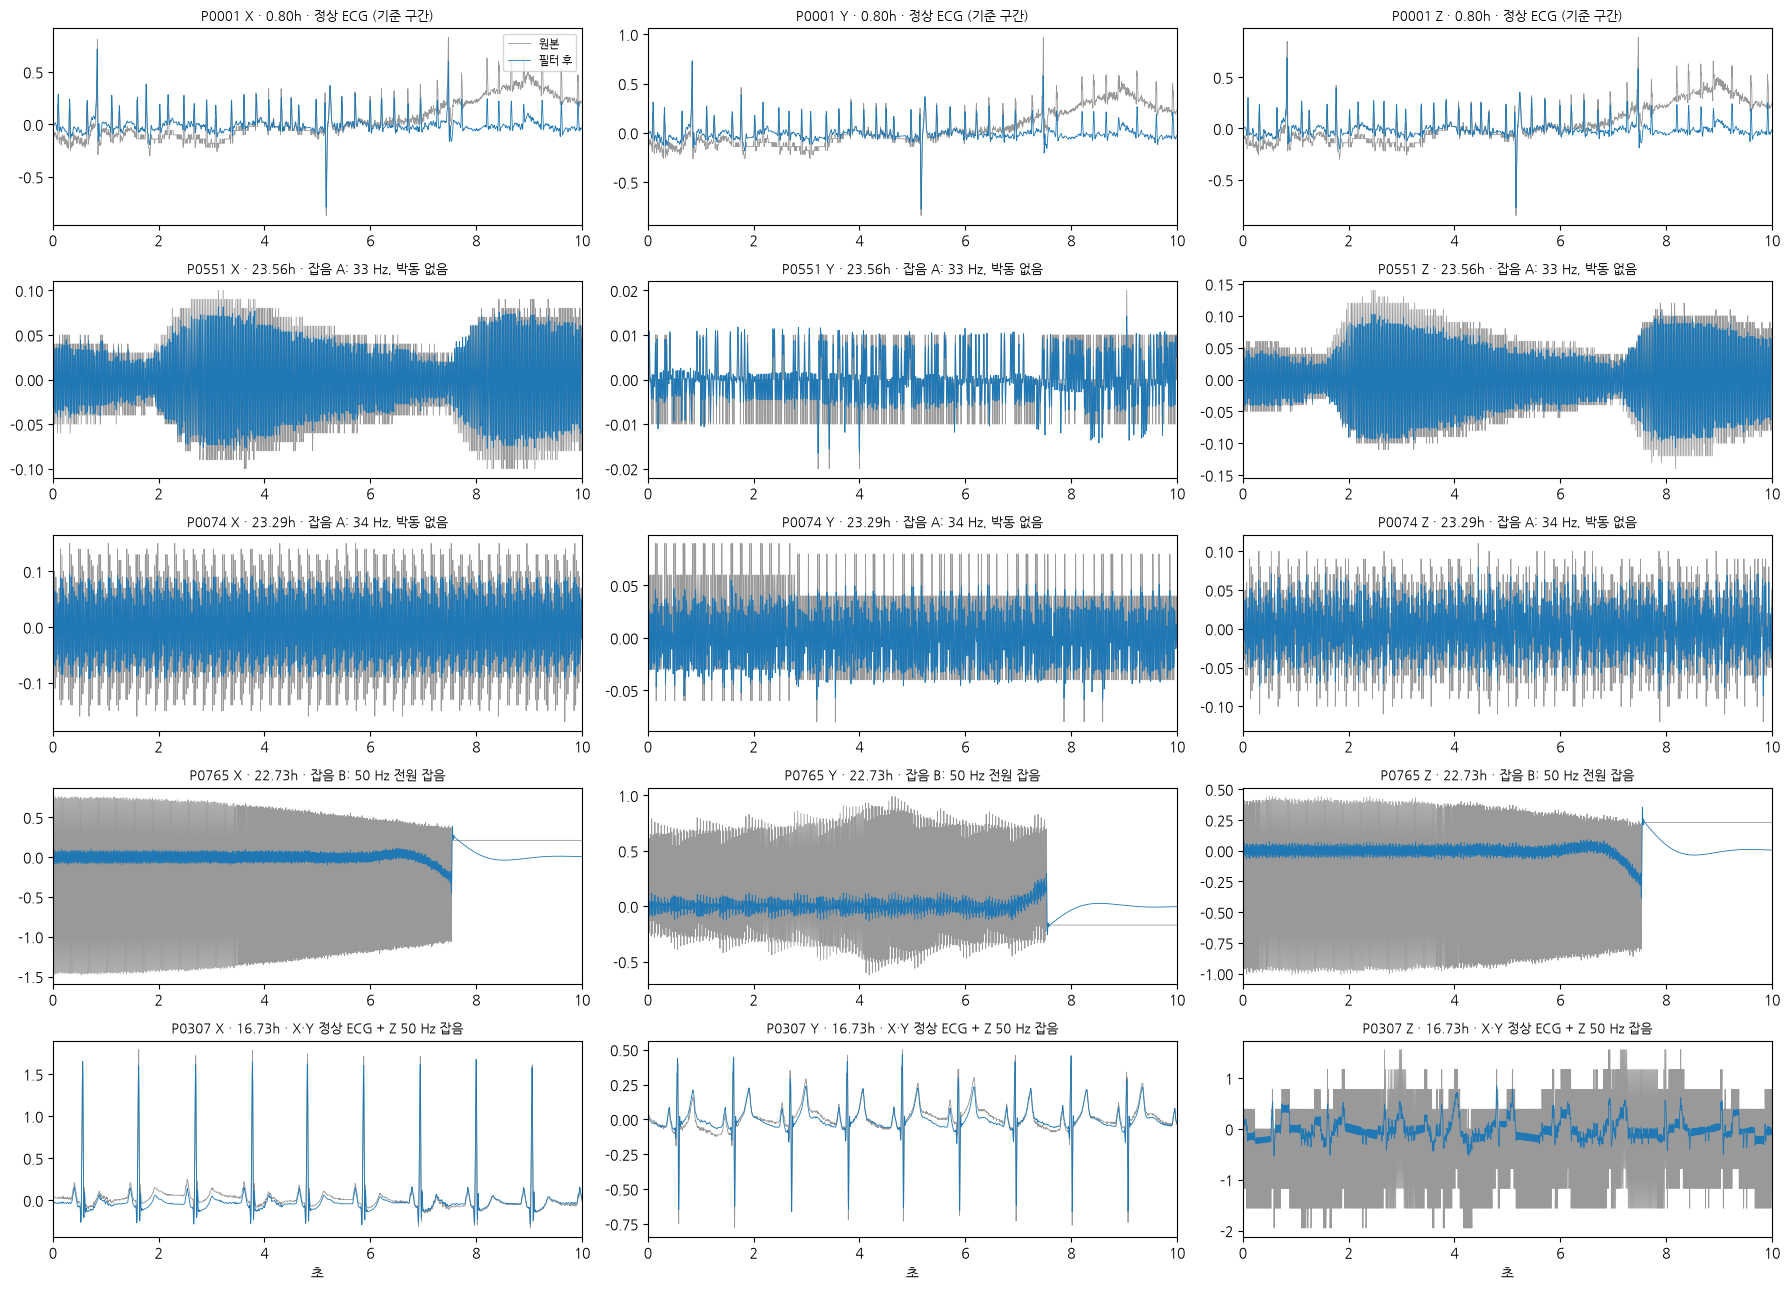

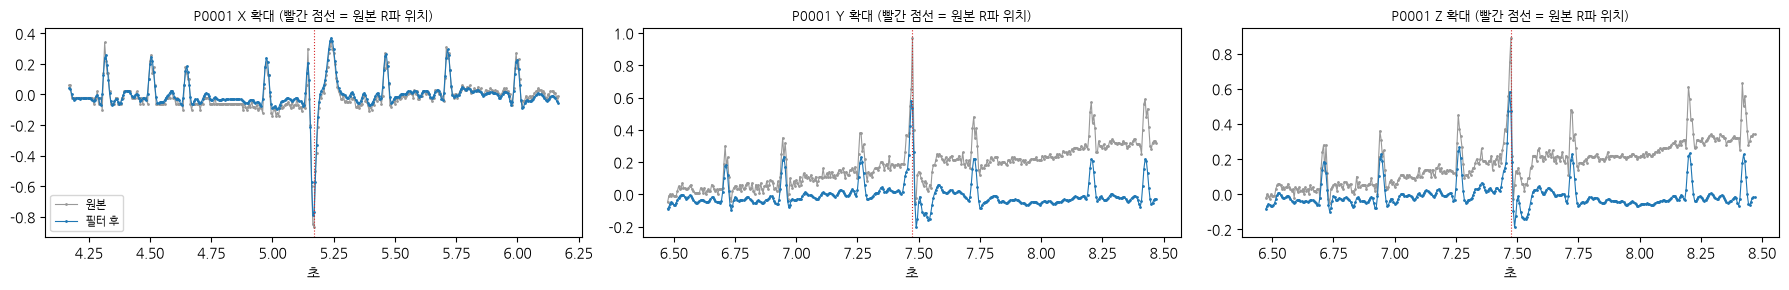

In [4]:
# 2-2. 필터 전후 그림: 정상 ECG는 모양·위치가 그대로인지, 잡음은 얼마나 남는지
fs = 200
WIN_SEC = 10          # 1단계 판정 창 길이 (초)
PAD_SEC = 60          # 앞뒤로 같이 읽어서 필터를 거는 길이 (가운데 10초에 창 끝 출렁임이 안 들어오게)
PEAK_SEARCH_MS = 100  # R파 위치 비교: 원본 R파 앞뒤 이 범위 안에서 필터 후 R파를 찾음
ZOOM_SEC = 1          # 확대 그림: R파 앞뒤 1초

CASES = [  # (환자, 10초 창 번호, 설명). 창 번호 None = 1단계 기준 구간 (정상 ECG)
    ("P0001", None, "정상 ECG (기준 구간)"),
    ("P0551", 8482, "잡음 A: 33 Hz, 박동 없음"),
    ("P0074", 8384, "잡음 A: 34 Hz, 박동 없음"),
    ("P0765", 8181, "잡음 B: 50 Hz 전원 잡음"),
    ("P0307", 6023, "X·Y 정상 ECG + Z 50 Hz 잡음"),
]


def read_window(pid, win_idx):
    """10초 창 + 앞뒤 1분을 읽고 DL 필터를 건 뒤, 가운데 10초의 [(유도, 원본, 필터 후), ...]를 돌려줌"""
    win, pad = WIN_SEC * fs, PAD_SEC * fs
    start = max(win_idx * win - pad, 0)                    # 기록 맨 앞이면 0부터
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                        sampfrom=start, sampto=(win_idx + 1) * win + pad)
    offset = win_idx * win - start                         # 읽은 신호 안에서 10초 창이 시작하는 위치

    leads = []
    for j, lead in enumerate(rec.sig_name):
        x_mv = rec.d_signal[:, j] / rec.adc_gain[j]        # 정수 → mV
        filt = dl_filter(x_mv, fs)[offset:offset + win]    # 앞뒤 1분까지 포함해서 필터 → 가운데 10초만
        raw = x_mv[offset:offset + win]
        raw = raw - np.median(raw)                         # 원본은 겹쳐 보려고 높이(직류 성분)만 0에 맞춤
        leads.append((lead, raw, filt))
    return leads


def r_peak_shift(raw, filt):
    """원본의 가장 큰 점(R파) 위치, 그리고 그 주변에서 찾은 필터 후 R파와의 위치 차이(ms)"""
    i_raw = int(np.argmax(np.abs(raw)))
    half = int(PEAK_SEARCH_MS / 1000 * fs)                 # 100 ms = 20샘플
    lo = max(i_raw - half, 0)
    i_filt = lo + int(np.argmax(np.abs(filt[lo:i_raw + half])))
    return i_raw, (i_filt - i_raw) * 1000 / fs


# ① 읽기 + 필터
cases = []
for pid, win_idx, desc in CASES:
    if win_idx is None:
        win_idx = int(np.load(WIN_DIR / f"{pid}.npz")["ref_idx"][0])   # P0001: X 유도 기준 창
    cases.append({"pid": pid, "win_idx": win_idx, "desc": desc, "leads": read_window(pid, win_idx)})

# ② 표: 크기가 얼마나 남았나, (정상 ECG만) R파 위치가 밀렸나
rows = []
for c in cases:
    for lead, raw, filt in c["leads"]:
        shift = r_peak_shift(raw, filt)[1] if (c["pid"], lead) in {("P0001", "X"), ("P0001", "Y"), ("P0001", "Z"), ("P0307", "X"), ("P0307", "Y")} else np.nan
        rows.append({"환자": c["pid"], "유도": lead, "설명": c["desc"],
                     "원본 범위(mV)": np.ptp(raw), "필터 후 범위(mV)": np.ptp(filt),
                     "남은 비율": np.ptp(filt) / np.ptp(raw), "R파 위치 차이(ms)": shift})
display(pd.DataFrame(rows).round(3))

# ③ 그림 1: 한 줄 = 환자 1명의 같은 10초, 칸 = 유도. 회색 = 원본, 파랑 = 필터 후
t = np.arange(WIN_SEC * fs) / fs
fig, axes = plt.subplots(len(cases), 3, figsize=(18, 2.6 * len(cases)), squeeze=False)
for row, c in zip(axes, cases):
    for ax in row[len(c["leads"]):]:
        ax.axis("off")                                     # 2유도 환자는 남는 칸 비움
    for ax, (lead, raw, filt) in zip(row, c["leads"]):
        ax.plot(t, raw, lw=0.6, color="0.6", label="원본")
        ax.plot(t, filt, lw=0.6, color="tab:blue", label="필터 후")
        ax.set_title(f"{c['pid']} {lead} · {c['win_idx'] * WIN_SEC / 3600:.2f}h · {c['desc']}", fontsize=9)
        ax.set_xlim(0, WIN_SEC)
axes[0, 0].legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("초")
plt.tight_layout()
plt.show()

# ④ 그림 2: P0001 R파 앞뒤 1초 확대 (점까지 찍어서 샘플 단위로 위치가 같은지 보기)
p0001 = cases[0]["leads"]
fig, axes = plt.subplots(1, len(p0001), figsize=(6 * len(p0001), 3), squeeze=False)
for ax, (lead, raw, filt) in zip(axes[0], p0001):
    i_raw, _ = r_peak_shift(raw, filt)
    view = slice(max(i_raw - ZOOM_SEC * fs, 0), i_raw + ZOOM_SEC * fs)
    ax.plot(t[view], raw[view], lw=0.8, marker=".", ms=2, color="0.6", label="원본")
    ax.plot(t[view], filt[view], lw=0.8, marker=".", ms=2, color="tab:blue", label="필터 후")
    ax.axvline(t[i_raw], color="tab:red", ls=":", lw=0.8)  # 원본 R파 위치
    ax.set_title(f"P0001 {lead} 확대 (빨간 점선 = 원본 R파 위치)", fontsize=9)
    ax.set_xlabel("초")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-24, 2-2)

- ✅ **정상 동리듬 ECG (P0307 X·Y)**: 필터 전후 박동 위치·모양(QRS, T파) 그대로, 바닥선만 평평해짐. R파 높이 거의 같음 (남은 비율 0.93·0.88은 바닥선 흔들림이 빠진 몫)
  - R파 위치: 가장 큰 박동 차이 X −5 ms · Y 0 ms. 같은 10초 박동 9개는 0·±1샘플이 섞여 나오고, 10초 전체를 겹쳐 맞추면 어긋남 0 → **필터가 신호를 밀지 않음** (앞뒤 두 번 걸기 확인). ±1샘플(5 ms)은 40 Hz 필터가 R파 꼭대기를 살짝 둥글게 만들어 가장 높은 점이 옆 샘플로 바뀐 것 (박동 9개 비교는 노트북 밖에서 따로 확인한 값)
- ⚠️ **P0001 기준 구간(0.8h)은 정상 ECG 예시로 부적절**: 심방세동(리듬 코드 1) + 세 유도 같은 신호(1단계 발견, 상관 0.999). 폭 5~10 ms의 아주 좁은 뾰족한 신호가 1초에 3~4번 반복됨. 필터 후 높이 0.9 → 0.58 mV (Y·Z): 40 Hz 위 성분이 많은 좁은 신호는 깎임 (Kligfield의 40 Hz 한계와 같은 현상). 폭 약 100 ms인 정상 QRS(P0307)는 줄지 않음. 코드의 설명 "정상 ECG (기준 구간)"은 위 이유로 맞지 않음
- **33 Hz 잡음 (P0551, P0074)**: 필터 후 59~80% 남음 (2-1의 87%보다 낮은 건 67 Hz 배음·계단 모양 성분이 깎여서) → 필터로 못 지움, 3단계에서 구간째 제외
- **50 Hz 잡음 (P0765)**: 50 Hz 떨림은 거의 사라짐. 남은 비율 0.34~0.51은 7.5초에 신호가 끊기는 곳(1단계 "멈춤") 때문: 필터가 끊기기 약 1초 **전**부터 휘고 끊긴 **뒤** 약 1.5초 출렁임 (앞뒤 두 번 걸어서 양쪽으로 번짐) → **버린 구간 옆으로 출렁임이 번지는 실제 사례** (2-3에서 다룸)
- **P0307 Z**: 50 Hz 잡음 아래 박동이 필터 후 희미하게 드러남 (X·Y 박동과 같은 시점). 이 창의 Z는 1단계에서 기기 신호(값 10개 이하)로 이미 제외됨

## 2-3. 필터를 어디에 걸지, 버린 구간 옆 출렁임

**논문 기준**
- 기록 전체(이어진 데이터)에 먼저 필터를 걸고 30초로 자른다: Widmann 2015 (45쪽), de Cheveigné 2019 (288쪽)
- 출렁임은 급한 변화(신호 끊김, 기기 신호 경계, 큰 튐)에서 생기고, 앞뒤 두 번 거는 필터는 변화 지점 앞뒤 모두로 번진다: Widmann 2015 (36·38쪽), de Cheveigné 2019 (285쪽)
- 신호가 끊긴 곳을 가로질러 필터를 걸지 말 것: Widmann 2015 (38·45쪽)
- 보조: 필터 출렁임은 "앞뒤로 몇 초까지" 가고, 보통 "충분한 여유 구간"을 둔다 (van Driel 2021, 6·11쪽, 숫자 없음)
- 구현 사례 (저널 아님): MNE-Python, EEGLAB은 기본으로 끊긴 곳 양쪽을 따로 필터함 (= 아래 B 방식)
- 몇 초를 더 버릴지 숫자는 두 논문 모두 없음 (Holter·심전도·뇌파 논문 추가 검색에서도 저널 근거 없음) → 논문이 권고한 방법(시험 신호로 필터 응답 확인, de Cheveigné 291쪽)으로 잼

**우리가 정하는 것 (🔧)**: 출렁임이 기록 해상도(0.01 mV)보다 작아지면 끝난 것으로 봄 (그보다 작으면 원래 기록에서도 구분 안 되는 크기)

**결과**: B 방식 + 덩어리 양 끝 3.5초 "사용 불가" (→ 2-4 정리)

| 소단계 | 내용 |
|---|---|
| ① | 시험 신호(계단, 한 점 튐)로 출렁임 길이 재기, 변화 크기별 |
| ② | 끊긴 곳 처리 비교: A 기록 전체 + 버린 구간 옆 여유 / B 끊긴 곳에서 나눠 따로 필터 / C 버린 구간을 직선으로 메운 뒤 전체 필터 (C는 예비 논문 방식, 참고용) |
| ③ | 버린 구간 옆 여유를 적용하면 30초 조각이 얼마나 줄어드는지 708명 전체로 세기 → 여유 확정 |


앞(초)        뒤(초)      
변화        계단 한 점 튐    계단 한 점 튐
크기(mV)                        
0.1     0.44  0.00  0.44  0.00
0.3     1.36  0.02  1.36  0.02
1.0     2.42  0.04  2.41  0.04
3.0     3.45  0.44  3.44  0.44
10.0    4.50  0.79  4.50  0.79
30.0    5.52  1.76  5.51  1.76

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

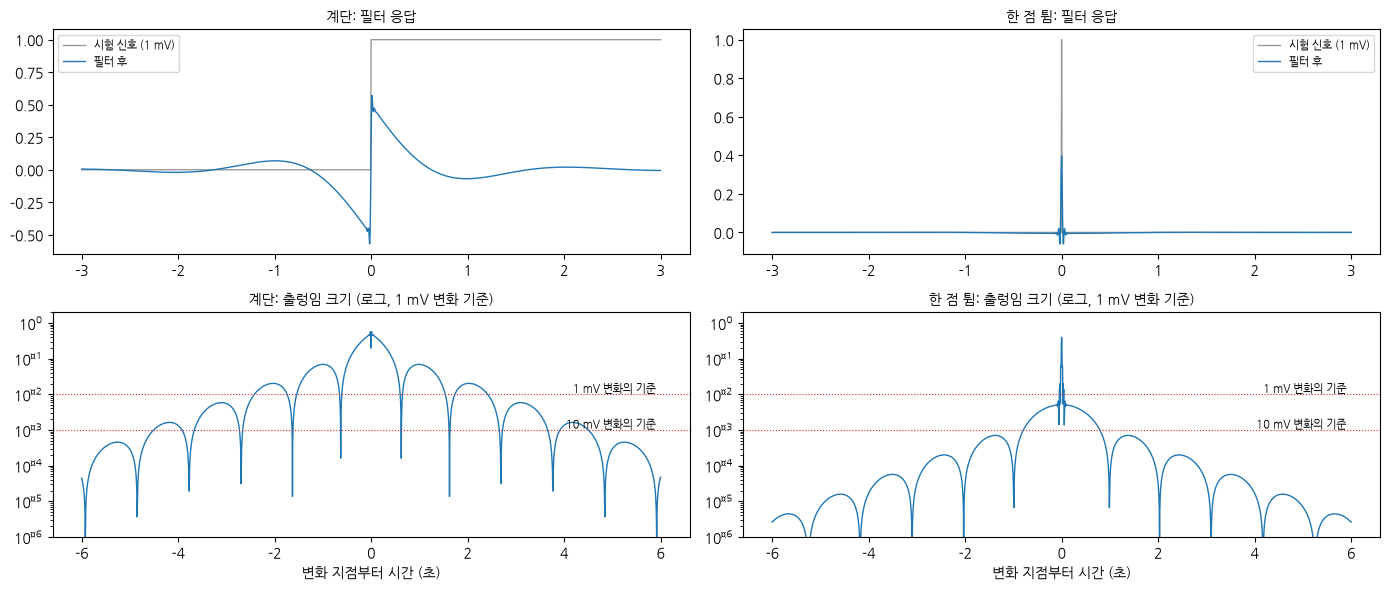

In [10]:
# 2-3 ① 필터 출렁임 길이: 급한 변화(계단·한 점 튐)를 넣었을 때 출렁임이 앞뒤로 몇 초 가는지
fs = 200
SIM_SEC = 60                             # 시험 신호 길이: 변화 지점 앞뒤 30초 (출렁임이 끝나기에 충분히 길게)
RESOLUTION_MV = 0.01                     # 기록 해상도 (정수 1 = 0.01 mV) → 이보다 작은 출렁임은 기록에서도 구분 안 됨
EVENT_MV = [0.1, 0.3, 1, 3, 10, 30]      # 시험할 변화 크기 (mV): 작은 끊김 ~ 1-6 ④의 수십 mV 튐


def test_signals():
    """가운데에 크기 1 mV의 급한 변화가 있는 시험 신호 2개와, 변화 지점 위치"""
    n = SIM_SEC * fs
    mid = n // 2
    step = np.zeros(n)
    step[mid:] = 1.0                     # 계단: 신호 높이가 뚝 바뀜 (끊김, 기기 신호 경계)
    spike = np.zeros(n)
    spike[mid] = 1.0                     # 한 점 튐
    return {"계단": step, "한 점 튐": spike}, mid


def ringing_span(y, mid, limit):
    """출렁임 |y|가 limit보다 큰 구간이 변화 지점 앞뒤로 몇 초까지 가는지 (앞, 뒤)"""
    over = np.flatnonzero(np.abs(y) > limit)
    if len(over) == 0:
        return 0.0, 0.0
    return (mid - over.min()) / fs, (over.max() - mid) / fs


# ① 시험 신호에 DL 필터 (2-1의 dl_filter). 대역 통과라 원래 신호의 높이(직류)는 사라지고 출렁임만 남음
signals, mid = test_signals()
responses = {name: dl_filter(x, fs) for name, x in signals.items()}

# ② 표: 변화 크기별로 출렁임이 해상도(0.01 mV)보다 커지는 구간 길이
#    필터는 크기에 비례해 반응하므로, 1 mV 시험 결과에서 기준을 (해상도 ÷ 변화 크기)로 바꿔 계산
rows = []
for name, y in responses.items():
    for event_mv in EVENT_MV:
        before, after = ringing_span(y, mid, RESOLUTION_MV / event_mv)
        rows.append({"변화": name, "크기(mV)": event_mv, "앞(초)": before, "뒤(초)": after})
span_table = pd.DataFrame(rows)
display(span_table.pivot(index="크기(mV)", columns="변화", values=["앞(초)", "뒤(초)"]).round(2))

# ③ 그림: 위 = 필터 응답 (변화 앞뒤 3초), 아래 = 응답 크기를 로그로 (작은 꼬리까지 보이게, de Cheveigné 그림 8 방식)
t = (np.arange(SIM_SEC * fs) - mid) / fs                       # 변화 지점 = 0초
fig, axes = plt.subplots(2, len(responses), figsize=(14, 6), squeeze=False)
for col, (name, y) in enumerate(responses.items()):
    near = np.abs(t) <= 3
    axes[0, col].plot(t[near], signals[name][near], color="0.6", lw=1, label="시험 신호 (1 mV)")
    axes[0, col].plot(t[near], y[near], color="tab:blue", lw=1, label="필터 후")
    axes[0, col].set_title(f"{name}: 필터 응답", fontsize=10)
    axes[0, col].legend(fontsize=8)

    wide = np.abs(t) <= 6
    axes[1, col].semilogy(t[wide], np.abs(y[wide]) + 1e-12, color="tab:blue", lw=1)
    for event_mv in (1, 10):                                     # 1 mV, 10 mV 변화일 때 "출렁임 끝" 기준선
        axes[1, col].axhline(RESOLUTION_MV / event_mv, color="tab:red", ls=":", lw=0.8)
        axes[1, col].text(5.9, RESOLUTION_MV / event_mv, f"{event_mv} mV 변화의 기준", ha="right", va="bottom", fontsize=8)
    axes[1, col].set_ylim(1e-6, 2)
    axes[1, col].set_title(f"{name}: 출렁임 크기 (로그, 1 mV 변화 기준)", fontsize=10)
    axes[1, col].set_xlabel("변화 지점부터 시간 (초)")
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-25, 2-3 ①)

- 출렁임이 해상도(0.01 mV)보다 큰 구간 (앞 / 뒤 각각, 초)

  | 변화 크기 | 계단 (끊김·기기 신호 경계) | 한 점 튐 |
  |---|---|---|
  | 0.1 mV | 0.44 | 0.00 |
  | 0.3 mV | 1.36 | 0.02 |
  | 1 mV | 2.42 | 0.04 |
  | 3 mV | 3.45 | 0.44 |
  | 10 mV | 4.50 | 0.79 |
  | 30 mV | 5.52 | 1.76 |

- **계단이 문제, 한 점 튐은 짧음**: 계단은 1 mV에서 앞뒤 약 2.4초, 크기가 3배 커질 때마다 약 1초씩 길어짐. 한 점 튐은 30 mV여도 약 1.8초
- **앞과 뒤가 같음**: 앞뒤 두 번 거는 필터라 변화 지점 **전**에도 같은 길이만큼 번짐 (Widmann 36쪽, de Cheveigné 285쪽과 일치)
- 출렁임 모양: 계단이 뾰족한 펄스(±0.5 mV)로 바뀌고 약 2초 주기로 출렁이며 줄어듦 = 0.5 Hz 고역 경계 근처 진동 (de Cheveigné: 출렁임은 차단 주파수 근처 주파수로 생김)
- 확인: 1 mV 계단 2.4초는 de Cheveigné의 어림값(1 ÷ 0.5 Hz = 약 2초)과 비슷하고, 2-2 P0765의 실제 출렁임(앞 약 1초, 뒤 약 1.5초)은 0.3~1 mV 계단 범위와 맞음
- → 몇 초를 더 버릴지는 **실제 데이터에서 버린 구간 경계의 높이 차이(계단 크기)가 얼마인지**에 달림 → 2-3 ②에서 확인

### 2-3 ②-1. 실제 경계의 계단 크기

- 1단계에서 버린 창과 깨끗한 창이 만나는 경계에서, 경계 앞 2초와 뒤 2초의 높이(중앙값) 차이 = 필터가 보는 계단 크기
- 무작위 환자 100명, 환자당 경계 최대 20개 (분포를 보려는 표본)
- 계단 크기 → 2-3 ①의 계단 응답으로 "출렁임이 해상도(0.01 mV)보다 큰 시간(초, 한쪽)"으로 바꿈
- 버린 이유별로 나눠 봄: 기록 시작 구간, 기기 신호, 멈춤, 평탄


환자 100명, 경계 457개, 3초


,경계 수,계단 중앙값(mV),계단 90%(mV),계단 99%(mV),출렁임 중앙값(초),출렁임 90%(초),출렁임 99%(초)
기기 신호,81.0,0.00,0.26,2.41,0.00,1.32,3.37
기록 시작 구간,275.0,0.06,0.51,1.72,0.35,2.12,3.12
멈춤,53.0,0.06,0.86,3.53,0.35,2.37,3.49
평탄,48.0,0.01,0.12,2.85,0.00,0.46,3.43
전체,457.0,0.04,0.42,3.00,0.25,1.43,3.44


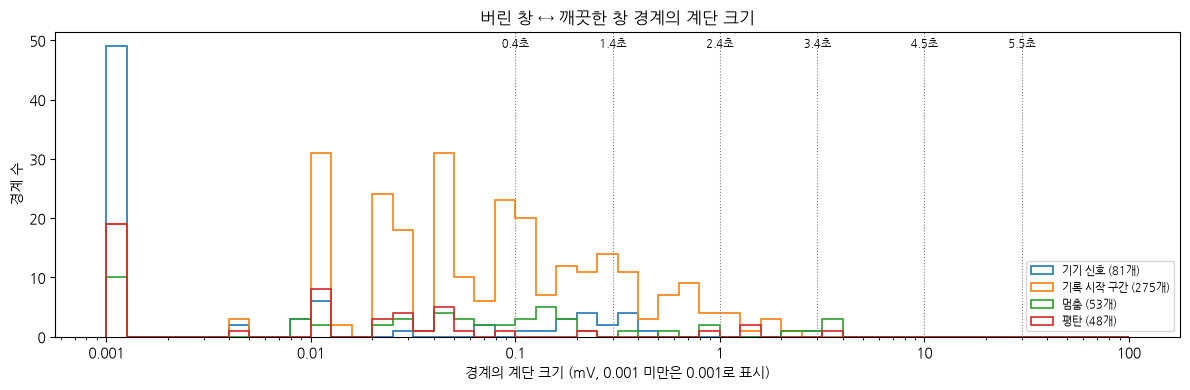

In [11]:
# 2-3 ②-1 실제 계단 크기: 1단계에서 버린 창과 깨끗한 창이 만나는 경계에서 신호 높이가 얼마나 바뀌나
#         → 2-3 ①의 계단 응답으로 "그 경계에서 출렁임이 몇 초 번지는지"로 바꿔서 봄
fs = 200
WIN_SEC = 10              # 1단계 판정 창 (초)
SIDE_SEC = 2              # 경계 양쪽에서 높이(중앙값)를 잴 길이 (초): 박동이 1개 이상 들어가는 길이
N_PATIENTS = 100          # 무작위로 고를 환자 수 (분포를 보려는 표본)
MAX_PER_PATIENT = 20      # 환자 1명당 볼 경계 수 상한 (한 사람이 결과를 다 차지하지 않게)
REASONS = {"start": "기록 시작 구간", "calib": "기기 신호", "stuck": "멈춤", "neri": "평탄"}   # 버린 이유 (앞에 있을수록 우선)

# 2-3 ①에서 만든 값 (①을 먼저 실행해야 함)
STEP_RESPONSE = responses["계단"]     # 1 mV 계단에 DL 필터를 건 결과
STEP_AT = mid                         # 그 시험 신호에서 계단 위치

rng = np.random.default_rng(0)        # 무작위 고정 (다시 돌려도 같은 환자·경계)


def find_boundaries(flags, lead):
    """한 유도에서 '버린 창 ↔ 깨끗한 창'이 바뀌는 경계 목록: [(창 k와 k+1 사이의 k, 버린 이유), ...]"""
    bad = flags["bad"][lead]
    boundaries = []
    for k in np.flatnonzero(bad[:-1] != bad[1:]):
        bad_win = k if bad[k] else k + 1                        # 경계 양쪽 중 버린 창
        reason = next((name for key, name in REASONS.items() if flags[key][lead, bad_win]), "기타")
        boundaries.append((int(k), reason))
    return boundaries


def sample_boundaries(pid):
    """환자 1명의 모든 유도에서 경계를 모으고, 많으면 MAX_PER_PATIENT개만 무작위로 고름
    돌려주는 값: 유도 이름 목록, [(유도 번호, k, 버린 이유), ...]"""
    flags = dict(np.load(WIN_DIR / f"{pid}.npz"))              # 1단계 창별 판정 (유도 수, 창 수)
    cands = []
    for lead in range(flags["bad"].shape[0]):
        for k, reason in find_boundaries(flags, lead):
            cands.append((lead, k, reason))
    if len(cands) > MAX_PER_PATIENT:
        picked = rng.choice(len(cands), size=MAX_PER_PATIENT, replace=False)
        cands = [cands[i] for i in picked]
    return flags["leads"], cands


def step_mv(pid, lead, k):
    """경계 앞 2초와 뒤 2초의 높이(중앙값) 차이 (mV) = 필터가 보는 계단 크기"""
    edge = (k + 1) * WIN_SEC * fs                               # 경계 위치 (샘플)
    side = SIDE_SEC * fs
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16, channels=[lead],
                        sampfrom=edge - side, sampto=edge + side)   # 경계 앞뒤 2초만 읽음
    x = rec.d_signal[:, 0] / rec.adc_gain[0]                    # 정수 → mV
    return abs(np.median(x[side:]) - np.median(x[:side]))


def ringing_sec(step):
    """계단 크기(mV)일 때 출렁임이 해상도(0.01 mV)보다 큰 시간 (초, 한쪽)
    필터는 크기에 비례해 반응하므로, 1 mV 계단 응답에서 기준을 (해상도 ÷ 계단 크기)로 바꿔 계산"""
    if step <= 0:
        return 0.0
    return ringing_span(STEP_RESPONSE, STEP_AT, RESOLUTION_MV / step)[1]


def summarize(df):
    """계단 크기의 중앙값·90%·99% 값과, 그때의 출렁임 시간"""
    q = df["계단(mV)"].quantile([0.5, 0.9, 0.99])
    return pd.Series({"경계 수": len(df),
                      "계단 중앙값(mV)": q[0.5], "계단 90%(mV)": q[0.9], "계단 99%(mV)": q[0.99],
                      "출렁임 중앙값(초)": ringing_sec(q[0.5]), "출렁임 90%(초)": ringing_sec(q[0.9]),
                      "출렁임 99%(초)": ringing_sec(q[0.99])})


# ① 환자별로 경계를 모으고 계단 크기 재기
t0 = time.time()
patients = rng.choice(qc_pass["pid"].to_numpy(), size=N_PATIENTS, replace=False)
rows = []
for pid in patients:
    lead_names, cands = sample_boundaries(pid)
    for lead, k, reason in cands:
        rows.append({"pid": pid, "유도": str(lead_names[lead]), "경계 창": k, "버린 이유": reason,
                     "계단(mV)": step_mv(pid, lead, k)})
steps = pd.DataFrame(rows)
steps["출렁임(초)"] = steps["계단(mV)"].apply(ringing_sec)
print(f"환자 {N_PATIENTS}명, 경계 {len(steps)}개, {time.time() - t0:.0f}초")

# ② 표: 버린 이유별 계단 크기와 출렁임 시간
table = pd.DataFrame({reason: summarize(g) for reason, g in steps.groupby("버린 이유")}).T
table.loc["전체"] = summarize(steps)
display(table.round(2))

# ③ 그림: 계단 크기 분포 (로그 축). 점선 위 숫자 = 그 크기일 때 출렁임 시간
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.logspace(-3, 2, 51)                                   # 0.001 ~ 100 mV
for reason, g in steps.groupby("버린 이유"):
    ax.hist(g["계단(mV)"].clip(1e-3, 100), bins=bins, histtype="step", lw=1.2, label=f"{reason} ({len(g)}개)")
top = ax.get_ylim()[1]
for mv in EVENT_MV:
    ax.axvline(mv, color="gray", ls=":", lw=0.8)
    ax.text(mv, top * 0.95, f"{ringing_sec(mv):.1f}초", ha="center", fontsize=8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))   # 로그 축 마이너스 기호 경고 방지
ax.set_xlabel("경계의 계단 크기 (mV, 0.001 미만은 0.001로 표시)")
ax.set_ylabel("경계 수")
ax.set_title("버린 창 ↔ 깨끗한 창 경계의 계단 크기")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-25, 2-3 ②-1, 무작위 100명 · 경계 457개)

| 버린 이유 | 경계 수 | 계단 중앙값 | 계단 90% | 계단 99% | 출렁임 중앙값 | 출렁임 90% | 출렁임 99% |
|---|---|---|---|---|---|---|---|
| 기록 시작 구간 | 275 | 0.06 mV | 0.51 mV | 1.72 mV | 0.35초 | 2.12초 | 3.12초 |
| 기기 신호 | 81 | 0.00 mV | 0.26 mV | 2.41 mV | 0초 | 1.32초 | 3.37초 |
| 멈춤 | 53 | 0.06 mV | 0.86 mV | 3.53 mV | 0.35초 | 2.37초 | 3.49초 |
| 평탄 | 48 | 0.01 mV | 0.12 mV | 2.85 mV | 0초 | 0.46초 | 3.43초 |
| **전체** | **457** | **0.04 mV** | **0.42 mV** | **3.00 mV** | **0.25초** | **1.43초** | **3.44초** |

- **실제 계단은 대부분 작음**: 경계의 절반은 0.04 mV 이하(출렁임 0.25초 이하), 90%가 0.42 mV 이하(1.4초 이하). 가장 큰 계단도 약 4 mV → **2-3 ①에서 걱정한 10~30 mV 계단은 없었음**
- **99%의 경계가 출렁임 3.5초 이하** (버린 이유와 상관없이 비슷)
- 기기 신호·평탄은 계단 0인 경계가 많음 (버린 구간이 깨끗한 구간과 같은 높이에 머묾)
- 경계의 60%(275개)가 기록 시작 구간: 환자·유도마다 기록 맨 앞에 하나씩 있어서. 영향은 기록 처음 몇 초뿐
- 환자당 경계 평균 약 4.6개 (중간에 버린 창이 적은 환자가 많음), 실행 3초
- ⚠️ 한계: 계단 크기를 경계 앞뒤 2초의 **중앙값 차이**로만 잼. 버린 창 **안**의 큰 튐이나 보정 펄스 모서리가 경계 가까이 있으면 그것도 출렁임을 만들 수 있음 → 2-3 ②-2에서 실제 경계 예시로 확인
- → 2-3 ②-2: 실제 계단 크기(90% 0.42 mV, 99% 3 mV)로 A·B·C 비교

### 2-3 ②-2. A·B·C 비교 (정답을 아는 신호로 시험)

- 깨끗한 정상 동리듬 ECG(P0307 X, 180초) 가운데 10초를 가짜 "버린 구간"(직선, 계단 0.42 mV · 3 mV = 2-3 ②-1의 90% · 99%)으로 바꿈
- 정답 = 가짜 구간 없이 건 필터 결과. 방법별 결과와 정답의 차이가 해상도(0.01 mV)보다 큰 곳이 깨끗한 쪽으로 몇 초까지 가는지 잼 (de Cheveigné 2019: 정답을 아는 신호로 시험)
- A: 기록 전체에 그대로 필터 / B: 버린 구간에서 나눠 양쪽에 따로 필터 (Widmann 2015 권고) / C: 버린 구간을 양쪽 높이를 잇는 직선으로 메운 뒤 전체 필터 (예비 논문 방식, 참고용)


출렁임(초)       최대 차이(mV)       
계단(mV)      0.42  3.00      0.42   3.00
방법                                     
A 전체        2.15  3.46     0.312  1.783
B 나눠서       1.68  1.68     0.180  0.180
C 직선으로 메움   0.51  0.51     0.066  0.066

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

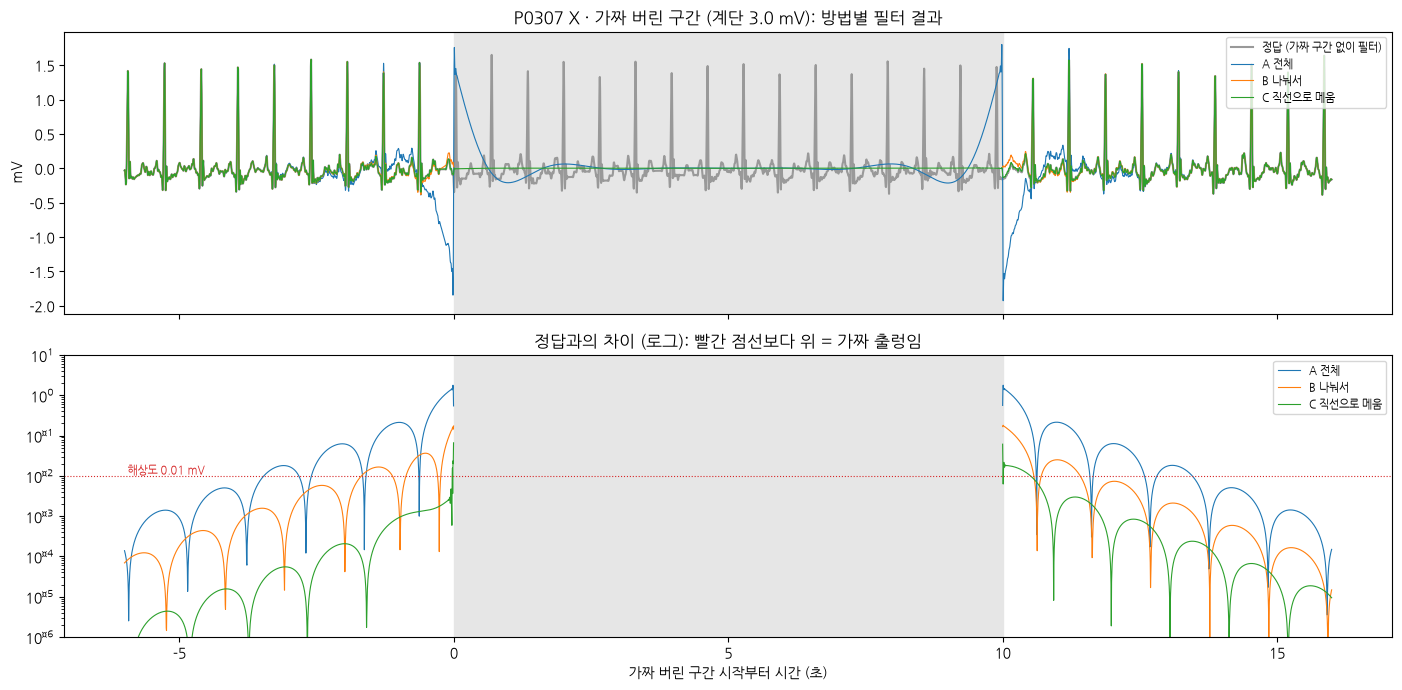

In [12]:
# 2-3 ②-2 A·B·C 비교: 정답을 아는 깨끗한 ECG에 가짜 "버린 구간"을 넣고, 방법별로 가짜 출렁임이 몇 초 남는지
fs = 200
WIN_SEC = 10                  # 1단계 판정 창 (초) = 가짜 버린 구간 길이
PID, LEAD = "P0307", 0        # 깨끗한 정상 동리듬 ECG (2-2에서 확인), 유도 X
CLEAN_SEC = 180               # 시험에 쓸 깨끗한 구간 길이 (가운데 10초를 가짜 버린 구간으로)
STEPS_MV = [0.42, 3.0]        # 가짜 버린 구간의 계단 크기: 2-3 ②-1의 90%, 99% 값
EDGE_SEC = 0.5                # C: 직선으로 이을 때 양쪽 높이를 잴 길이 (중앙값이라 박동 꼭대기에 안 걸림)
# RESOLUTION_MV (0.01 mV)는 2-3 ①, dl_filter는 2-1에서 만든 것


def runs(mask):
    """True가 이어진 구간들의 slice 목록"""
    change = np.flatnonzero(np.diff(np.r_[False, mask, False].astype(int)))
    return [slice(s, e) for s, e in zip(change[::2], change[1::2])]


def find_clean_run(pid, lead, n_windows):
    """1단계 판정에서 깨끗한 창이 n_windows개 연달아 나오는 첫 구간의 시작 창 번호"""
    bad = np.load(WIN_DIR / f"{pid}.npz")["bad"][lead]
    run = 0
    for k, is_bad in enumerate(bad):
        run = 0 if is_bad else run + 1
        if run == n_windows:
            return k - n_windows + 1
    raise ValueError(f"{pid}: 깨끗한 창 {n_windows}개 연속 구간 없음")


def read_mv(pid, lead, start_win, n_windows):
    """창 번호 start_win부터 창 n_windows개를 mV로 읽기"""
    start = start_win * WIN_SEC * fs
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16, channels=[lead],
                        sampfrom=start, sampto=start + n_windows * WIN_SEC * fs)
    return rec.d_signal[:, 0] / rec.adc_gain[0]


def insert_fake_bad(x, bad, step):
    """bad 구간을 '깨끗한 구간 높이 + step mV'의 직선으로 바꿈 (멈춤·기기 신호 흉내)"""
    y = x.copy()
    y[bad] = np.median(x[~bad]) + step
    return y


def method_a(x, bad):
    """A: 기록 전체에 그대로 필터 (버린 구간을 가로질러 걸림)"""
    return dl_filter(x, fs)


def method_b(x, bad):
    """B: 버린 구간에서 나눠, 양쪽 깨끗한 덩어리에 따로 필터 (버린 구간은 비움)"""
    y = np.full_like(x, np.nan)
    for piece in runs(~bad):
        y[piece] = dl_filter(x[piece], fs)
    return y


def method_c(x, bad):
    """C: 버린 구간을 양쪽 깨끗한 구간 높이를 잇는 직선으로 메워 계단을 없앤 뒤 전체에 필터"""
    y = x.copy()
    n_edge = int(EDGE_SEC * fs)
    for piece in runs(bad):
        left = np.median(x[max(piece.start - n_edge, 0):piece.start])
        right = np.median(x[piece.stop:piece.stop + n_edge])
        y[piece] = np.linspace(left, right, piece.stop - piece.start)
    return dl_filter(y, fs)


def contamination_sec(diff, bad):
    """버린 구간 경계에서 |정답과의 차이|가 해상도보다 큰 곳이 깨끗한 쪽으로 몇 초까지 가는지 (양쪽 중 긴 쪽)"""
    piece = runs(bad)[0]
    left = np.flatnonzero(np.abs(diff[:piece.start]) > RESOLUTION_MV)
    right = np.flatnonzero(np.abs(diff[piece.stop:]) > RESOLUTION_MV)
    left_sec = (piece.start - left.min()) / fs if len(left) else 0.0
    right_sec = (right.max() + 1) / fs if len(right) else 0.0
    return max(left_sec, right_sec)


METHODS = {"A 전체": method_a, "B 나눠서": method_b, "C 직선으로 메움": method_c}

# ① 깨끗한 구간 읽기 + 가운데 10초를 가짜 버린 구간으로 표시
n_windows = CLEAN_SEC // WIN_SEC
x = read_mv(PID, LEAD, find_clean_run(PID, LEAD, n_windows), n_windows)
win = WIN_SEC * fs
bad = np.zeros(len(x), dtype=bool)
bad[(n_windows // 2) * win:(n_windows // 2 + 1) * win] = True
reference = dl_filter(x, fs)                                    # 정답: 가짜 구간 없이 건 필터 결과

# ② 계단 크기 × 방법별로 필터 → 정답과 비교 (버린 구간 안은 비교하지 않음)
rows, outputs = [], {}
for step in STEPS_MV:
    x_bad = insert_fake_bad(x, bad, step)
    for name, method in METHODS.items():
        y = method(x_bad, bad)
        diff = np.where(bad, 0.0, y - reference)
        outputs[(step, name)] = y
        rows.append({"계단(mV)": step, "방법": name,
                     "출렁임(초)": contamination_sec(diff, bad), "최대 차이(mV)": np.max(np.abs(diff))})
result = pd.DataFrame(rows)
display(result.pivot(index="방법", columns="계단(mV)", values=["출렁임(초)", "최대 차이(mV)"]).round(3))

# ③ 그림 (계단 3 mV): 위 = 정답과 방법별 결과, 아래 = 정답과의 차이 (로그). 회색 칸 = 가짜 버린 구간
step = STEPS_MV[-1]
piece = runs(bad)[0]
view = slice(piece.start - 6 * fs, piece.stop + 6 * fs)        # 버린 구간 앞뒤 6초
t = (np.arange(len(x)) - piece.start) / fs                      # 버린 구간 시작 = 0초
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(t[view], reference[view], color="0.6", lw=1.5, label="정답 (가짜 구간 없이 필터)")
for name in METHODS:
    axes[0].plot(t[view], outputs[(step, name)][view], lw=0.8, label=name)
    diff = np.abs(np.where(bad, np.nan, outputs[(step, name)] - reference))
    axes[1].semilogy(t[view], diff[view] + 1e-9, lw=0.8, label=name)
for ax in axes:
    ax.axvspan(0, WIN_SEC, color="0.9")
axes[1].axhline(RESOLUTION_MV, color="tab:red", ls=":", lw=0.8)
axes[1].text(t[view][0], RESOLUTION_MV, " 해상도 0.01 mV", va="bottom", fontsize=8, color="tab:red")
axes[1].set_ylim(1e-6, 10)
axes[0].set_title(f"{PID} X · 가짜 버린 구간 (계단 {step} mV): 방법별 필터 결과")
axes[1].set_title("정답과의 차이 (로그): 빨간 점선보다 위 = 가짜 출렁임")
axes[1].set_xlabel("가짜 버린 구간 시작부터 시간 (초)")
axes[0].set_ylabel("mV")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-25, 2-3 ②-2, P0307 X · 가짜 버린 구간 10초)

**한 일**: 깨끗한 ECG 가운데 10초를 일부러 망가뜨리고(평평한 직선 + 계단), 세 방법으로 필터를 건 뒤 "망가뜨리기 전 정답"과 비교함

| 방법 | 출렁임 (계단 0.42 mV) | 출렁임 (계단 3 mV) | 정답과 최대 차이 (0.42 / 3 mV) |
|---|---|---|---|
| A 전체에 그대로 | 2.15초 | 3.46초 | 0.31 / 1.78 mV |
| **B 나눠서 따로** | **1.68초** | **1.68초** | **0.18 / 0.18 mV** |
| C 직선으로 메움 | 0.51초 | 0.51초 | 0.07 / 0.07 mV |

- **A는 계단이 클수록 길고 크게 출렁임**: 3 mV에서 3.46초 (②-1 예측 3.44초와 일치), 최대 1.78 mV = QRS 높이만큼 휨 → 모델이 가짜 파형을 배울 수 있음
- **B는 계단 크기와 상관없이 1.68초**: 계단을 아예 필터에 넣지 않아서. 남는 1.68초는 덩어리 **끝**이라 필터가 참고할 앞뒤 신호가 한쪽만 있어서 생김 → 여유 하나로 모든 경계 처리 가능
- **C가 가장 짧지만** 근거가 예비 논문(arXiv)뿐이고, 버린 구간 안에 큰 튐이 있으면 직선의 양 끝 높이가 틀어질 수 있음 → 참고용
- ⚠️ 한계: 환자 1명 · 유도 1개 · 평탄한 가짜 구간 1개로만 시험
- → **B 방식 선택** (Widmann 2015 원칙과 같음). 덩어리 끝을 몇 초 버릴지는 ③에서 손실로 확인

### 2-3 ③. 여유 초별 30초 조각 수 (1단계 통과 708명 전체)

- B 방식: 1단계에서 깨끗한 창이 이어진 덩어리마다 따로 필터 → 덩어리 양 끝에 출렁임이 남음
- 덩어리 양 끝을 여유만큼 버리고, 남은 길이에 30초 조각이 몇 개 들어가는지 셈
- 여유: 0초(비교 기준) / 1초 / 2초(②-2 B 결과 1.68초 올림) / 3.5초(②-1 99% 계단에서 A의 출렁임)
- (가) 3유도 모두 깨끗한 구간 = 기본 (3채널 입력, 가장 흔한 방식) / (나) 유도별 = 참고
- 확인할 것: 여유를 늘려도 손실이 작은지, SCD와 생존 환자의 손실이 비슷한지


환자 708명, 1초
전체 30초 조각 수


,0초,1초,2초,3.5초
그룹,,,,
3유도 모두,1957235,1956179,1956179,1956179
X,1963632,1963024,1963024,1963024
Y,1960772,1959909,1959909,1959909
Z,1878351,1877556,1877556,1877556


여유 0초 대비 줄어든 비율 (%)


,0초,1초,2초,3.5초
그룹,,,,
3유도 모두,0.0,0.05,0.05,0.05
X,0.0,0.03,0.03,0.03
Y,0.0,0.04,0.04,0.04
Z,0.0,0.04,0.04,0.04


SCD                      SCD     생존
1초 손실%         median   0.00   0.00
               q90      0.16   0.04
               max      3.80   3.17
2초 손실%         median   0.00   0.00
               q90      0.16   0.04
               max      3.80   3.17
3.5초 손실%       median   0.00   0.00
               q90      0.16   0.04
               max      3.80   3.17
사용 시간(h, 3.5초) median  23.02  23.32
               q90     23.98  23.98
               max     23.98  23.98

여유 0초에서 조각 0개인 환자: 0 명


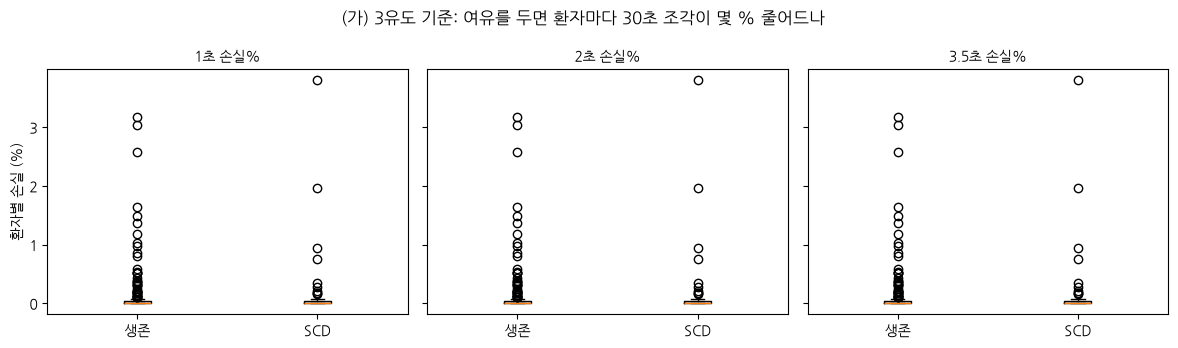

In [13]:
# 2-3 ③ 여유 초별 30초 조각 수: 깨끗한 덩어리 양 끝을 여유만큼 버리면 30초 조각이 얼마나 줄어드나
WIN_SEC = 10                                   # 1단계 판정 창 (초)
SEG_SEC = 30                                   # DL 입력 조각 길이 (초)
MARGINS_SEC = [0, 1, 2, 3.5]                   # 덩어리 양 끝에서 버릴 여유 (초). 0 = 비교 기준
MARGIN_COLS = [f"{m}초" for m in MARGINS_SEC]
GROUPS = ["3유도 모두", "X", "Y", "Z"]          # (가) 3유도 모두 깨끗 = 기본 / (나) 유도별 = 참고
# runs()는 2-3 ②-2에서 만든 것


def clean_masks(pid):
    """그룹별 '깨끗한 창' 표시 {그룹: (창 수,) True/False}: 3유도 모두 깨끗 + 유도별"""
    flags = np.load(WIN_DIR / f"{pid}.npz")
    bad = flags["bad"]                                          # (유도 수, 창 수), True = 1단계에서 사용 불가
    masks = {"3유도 모두": ~bad.any(axis=0)}                    # 한 유도라도 나쁘면 그 창은 사용 불가
    for j, lead in enumerate(flags["leads"]):
        masks[str(lead)] = ~bad[j]
    return masks


def run_lengths_sec(clean):
    """깨끗한 창이 이어진 덩어리들의 길이 (초) = B 방식에서 따로 필터를 거는 단위"""
    return np.array([(r.stop - r.start) * WIN_SEC for r in runs(clean)])


def count_segments(lengths, margin):
    """덩어리마다 양 끝을 margin초씩 버리고, 남은 길이에 30초 조각이 몇 개 들어가나 (합계)"""
    usable = np.maximum(lengths - 2 * margin, 0)
    return int((usable // SEG_SEC).sum())


def q90(s):
    """90% 값 (표에서 이름이 'q90'으로 보이게)"""
    return s.quantile(0.9)


# ① 환자 × 그룹마다 여유별 조각 수
t0 = time.time()
rows = []
for pid, scd in zip(qc_pass["pid"], qc_pass["label_scd"]):
    for group, clean in clean_masks(pid).items():
        lengths = run_lengths_sec(clean)
        row = {"pid": pid, "SCD": scd, "그룹": group, "덩어리 수": len(lengths)}
        for m, col in zip(MARGINS_SEC, MARGIN_COLS):
            row[col] = count_segments(lengths, m)
        rows.append(row)
seg = pd.DataFrame(rows)
print(f"환자 {seg['pid'].nunique()}명, {time.time() - t0:.0f}초")

# ② 표 1: 전체 조각 수와, 여유 0초 대비 줄어든 비율(%)
total = seg.groupby("그룹")[MARGIN_COLS].sum().loc[GROUPS]
loss = 100 * (1 - total.div(total[MARGIN_COLS[0]], axis=0))
print("전체 30초 조각 수")
display(total)
print("여유 0초 대비 줄어든 비율 (%)")
display(loss.round(2))

# ③ 표 2: (가) 3유도 기준, 환자별 손실(%)과 사용 가능 시간을 SCD / 생존으로 나눠 봄
main = seg[seg["그룹"] == "3유도 모두"].copy()
base = main[MARGIN_COLS[0]].replace(0, np.nan)                  # 여유 0초에도 조각이 0개인 환자는 비율 계산에서 뺌
loss_cols = []
for col in MARGIN_COLS[1:]:
    main[f"{col} 손실%"] = 100 * (1 - main[col] / base)
    loss_cols.append(f"{col} 손실%")
main["사용 시간(h, 3.5초)"] = main[MARGIN_COLS[-1]] * SEG_SEC / 3600
main["SCD"] = main["SCD"].map({0: "생존", 1: "SCD"})
display(main.groupby("SCD")[loss_cols + ["사용 시간(h, 3.5초)"]].agg(["median", q90, "max"]).round(2).T)
print("여유 0초에서 조각 0개인 환자:", int(base.isna().sum()), "명")

# ④ 그림: 환자별 손실(%) 분포, 여유별 · SCD / 생존
fig, axes = plt.subplots(1, len(loss_cols), figsize=(12, 3.5), sharey=True)
for ax, col in zip(axes, loss_cols):
    data = [main.loc[main["SCD"] == g, col].dropna() for g in ["생존", "SCD"]]
    ax.boxplot(data)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["생존", "SCD"])
    ax.set_title(col, fontsize=10)
axes[0].set_ylabel("환자별 손실 (%)")
fig.suptitle("(가) 3유도 기준: 여유를 두면 환자마다 30초 조각이 몇 % 줄어드나")
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-25, 2-3 ③, 1단계 통과 708명 전체, 실행 1초)

**한 일**: 깨끗한 덩어리 양 끝을 0 / 1 / 2 / 3.5초씩 잘라내면 30초 조각이 얼마나 줄어드는지 셈

| 기준 | 여유 0초 | 1초 | 2초 | 3.5초 | 줄어든 비율 |
|---|---|---|---|---|---|
| (가) 있는 유도 모두 깨끗 | 1,957,235 | 1,956,179 | 1,956,179 | 1,956,179 | 0.05% |
| (나) X만 | 1,963,632 | 1,963,024 | 1,963,024 | 1,963,024 | 0.03% |
| (나) Y만 | 1,960,772 | 1,959,909 | 1,959,909 | 1,959,909 | 0.04% |
| (나) Z만 | 1,878,351 | 1,877,556 | 1,877,556 | 1,877,556 | 0.04% |

- **손실이 거의 없음**: 여유를 3.5초로 해도 약 196만 개 중 약 1,000개(0.05%)만 줄어듦. 환자당 약 23시간을 그대로 씀
- **1·2·3.5초 결과가 똑같은 이유**: 덩어리 길이가 항상 10초 단위(10초 창 판정)라서, 30초로 나눈 나머지가 0·10·20초 중 하나. 나머지가 10·20초면 양 끝을 몇 초 잘라도 나머지에서 빠짐. 길이가 딱 30초의 배수인 덩어리만 조각 1개를 잃음 → **여유가 5초 이하면 몇 초든 결과가 같음**
- **SCD와 생존의 손실이 비슷함** ((가) 기준, 환자별 손실)

  | | 중앙값 | 90% | 최대 | 사용 시간 중앙값 |
  |---|---|---|---|---|
  | 생존 | 0% | 0.04% | 3.2% | 23.3시간 |
  | SCD | 0% | 0.16% | 3.8% | 23.0시간 |

- **(가) 기준으로 해도 손해가 작음**: X 하나만 볼 때보다 0.3% 적음 → 3채널 입력(가장 흔한 방식)으로 가도 됨
- ⚠️ **Z 유도가 없는 환자 30명 발견** (생존 27, SCD 3, 기록이 X·Y만 있음). 그래서 (나) Z가 (가)보다 적게 나옴. 이 30명은 코드의 "3유도 모두"가 실제로 "X·Y 둘 다"로 계산됨 (위 표 이름을 "있는 유도 모두"로 읽기)
  - 처리: 3채널 입력에서 Z = 0으로 채움 (npj Cardiovasc Health 2024), 팀 비교 실험으로 성능 확인 → 2단계 기준 표
- 여유 0초에서도 조각이 0개인 환자: 0명
- ⚠️ 이 개수는 **깨끗한 덩어리 안에서 30초를 자유롭게 자른 경우**. 6단계에서 기록 처음부터 30초 고정 칸(10초 창 3개)으로 자르면, 덩어리 끝 여유 때문에 끝 칸이 통째로 빠져 손실이 더 클 수 있음 → 6단계에서 두 방식 개수를 비교하고 정함
- → **덩어리 양 끝 3.5초로 확정** (넉넉하게, 실제 경계 99%의 출렁임까지 덮는 값). 3단계에서 버리는 창이 늘면 다시 실행

## 2-4. 2단계 정리 (쉬운 설명)

### 한 줄 요약
**ECG에서 잡음을 거르는 필터를 정했고, 필터가 만드는 부작용(출렁임)이 데이터를 망가뜨리지 않게 거는 방법까지 정했다. 버리는 데이터는 0.05%뿐이다.**

### 먼저 알아 둘 말

| 말 | 뜻 |
|---|---|
| 필터 | 신호에서 필요 없는 주파수를 걸러내는 계산. 여기서는 0.5 Hz보다 느린 흔들림(숨·몸 움직임)과 40 Hz보다 빠른 떨림(전기·근육 잡음)을 지움 |
| 유도 (X·Y·Z) | 같은 심장을 서로 다른 방향에서 잰 신호. Holter는 보통 3개를 동시에 기록 |
| 창 | 1단계에서 "쓸 수 있나"를 판정한 10초 단위 |
| 덩어리 | 깨끗한 창이 끊기지 않고 이어진 구간 |
| 계단 | 버린 구간과 깨끗한 구간이 만나는 곳에서 신호 높이가 뚝 바뀌는 것 |
| 출렁임 | 필터가 계단을 지나갈 때 앞뒤로 생기는 가짜 물결. 종을 치면 "웅~" 하고 울리는 것과 비슷 |
| 30초 조각 | 딥러닝 모델에 넣는 단위 |

### 정한 것

| 무엇 | 정한 것 | 왜 | 근거 |
|---|---|---|---|
| 필터 | 0.5–40 Hz, 버터워스 4차, 앞뒤로 두 번 | 같은 MUSIC 데이터 논문이 쓴 대역. 앞뒤로 두 번 걸면 박동 위치가 밀리지 않음 | 📄 Ramírez 2017, Kligfield 2007, Luo 2010 |
| 필터 거는 위치 | 버린 구간에서 끊고, 깨끗한 덩어리마다 따로 | 끊긴 곳을 가로질러 걸면 출렁임이 깨끗한 쪽으로 번짐 (시험에서 최대 3.5초, QRS 높이만큼 휨) | 📄 Widmann 2015, de Cheveigné 2019 |
| 덩어리 끝 여유 | 양 끝 3.5초 "사용 불가" | 따로 걸어도 덩어리 끝 약 1.7초는 조금 틀어짐. 넉넉하게 3.5초 | 🔧 숫자는 논문에 없어 우리 데이터로 정함 (손실 0.05%) |
| 유도 기준 | 있는 유도가 모두 깨끗한 30초만 사용 | 모델에 3유도를 한꺼번에 넣는 게 가장 흔한 방식. 손해는 0.3% | ✋ 팀 계획 (저널 기준 없음) |
| Z 없는 30명 | Z 자리를 0으로 채움 | 30명(SCD 3명 포함)을 버리지 않으려고 | 📄 npj Cardiovasc Health 2024 |

### 숫자로 본 결과
- 필터: 1 Hz 신호는 99.7% 남음 (기준 94.4% 이상), 정상 박동 위치는 그대로
- 실제 경계 계단: 절반은 0.04 mV 이하로 아주 작음, 99%가 3 mV 이하
- 30초 조각: 약 196만 개 → 여유 3.5초 적용 후 약 1,000개(0.05%) 줄어듦
- SCD·생존 환자 모두 손실 중앙값 0%, 환자당 약 23시간 사용 가능

### 아직 남은 일
- 3단계: 필터로 못 지우는 잡음(33 Hz 기계 떨림 등) 구간을 신호 품질 검사로 찾기 → 그 뒤 2-3 ③ 다시 실행
- 6단계: 30초 조각 목록에 "사용 가능 여부"와 "유도 수(2/3)"를 같이 저장
- 6단계: 30초를 덩어리 안에서 자유롭게 자를지, 고정 칸으로 자를지 정하기 (위 손실 0.05%는 자유롭게 자른 경우)
- DL: "3유도 환자만" vs "2·3유도 섞음 (Z = 0)" 성능 비교